# Road to Safety — Frozen calibration transfer stress test v1

## tl;dr

**Transfer was not demonstrated.** The saved sigmoid correction worsens log loss and Brier in both 2020 and 2021, and increases underprediction. No estimator, calibrator, prevalence, threshold or feature is fitted or changed.

The saved base estimator was trained on 1999–2016; its selected sigmoid correction was fitted on 2017–2018. This scoring-only comparison covers **163,580 candidate collisions**, including **3,230 fatal collisions**. These years had already been inspected and evaluated: this is a **reused retrospective stress test**, not independent prospective validation.

The original baseline and completed calibration development run remain unchanged. See [full results](../docs/calibration_stress_v1_results.md), [protocol](../docs/calibration_stress_v1_protocol.md), [experiment card](../models/calibration_stress_v1_card.md), and [independent validation](../docs/calibration_stress_v1_validation.md).

## Context & Methods

### Key Assumptions

The unit is a release-scoped candidate collision; the target is fatal versus nonfatal injury conditional on being a recorded fatal/injury collision. There is no exposure/non-crash denominator, individual-mortality probability, local geography or causal intervention effect.

Use the exact saved 2019 development-fold coefficients and dictionary-fixed eight-feature encoding. Unknown, other and unavailable codes stay distinct. All eligible 2020–2021 collisions are retained; unsupported/null/conflicting categories reject scoring. Year/source IDs/outcomes/diagnostics are not predictors.

For base logit`z`, compare unchanged`expit(z)`, saved sigmoid`expit(a*z+b)`, and the constant training-prevalence comparator. The selected sigmoid has a=0.9697790551002594 and b=−0.1386345837431384. No intercept-only candidate, optimization, resampling, weighting, threshold analysis or new selection occurs.

Favorable directional transfer requires sigmoid-minus-unchanged log loss<−1e−10 and Brier≤1e−10 **in both years**. Pooled or macro scores cannot override a failed year. Mean prediction gaps, O/E, reliability and ECE are diagnostics; an extra gap criterion is not used in the gate.

Report both frozen bin schemes with empty/sparse bins, separate year/pooled metrics, descriptive two-year macro means/SD, and separate overlapping unknown/other/unavailable availability flags. Sparse is n<100 or fatal<5. No confidence interval or significance claim is supplied.

The source years were already inspected, and this comparison was chosen after their underprediction was known. Freezing the new protocol prevents tuning but does not undo that prior exposure.

### Reproduction

For the existing preserved version:

```bash
.venv/bin/python -m road_to_safety.validate_calibration_stress_v1
```

To reproduce scoring in a separate working copy retaining the pinned inputs and with no completed stress manifest:

```bash
uv sync --locked --python 3.13 --extra notebook
MPLCONFIGDIR=/tmp/road-to-safety-mpl .venv/bin/python -m road_to_safety.score_calibration_stress_v1
```

This notebook verifies the passed independent audit receipt and its bound saved artifacts, then displays results. It does not refit or rescore merely to open the notebook.

## Data

### Frozen parameters and preservation

In [1]:
from pathlib import Path
import json,hashlib
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
folder=ROOT/'data/derived/calibration_stress_v1'
protocol=json.loads((ROOT/'data/reference/calibration_stress_v1_protocol.json').read_text())
model=json.loads((folder/'archived_model_2019.json').read_text())
print('Frozen:',protocol['frozen_at_utc'])
print('Evidence:',protocol['evidence_status'])
print('Saved sigmoid:',model['calibrators']['sigmoid']['slope'],model['calibrators']['sigmoid']['intercept'])
print('Saved training prevalence:',model['train_prevalence'])
def table(name): return pd.read_csv(ROOT/'reports/tables'/name,dtype={'population':str})
def figure(name): display(Image(filename=str(ROOT/'reports/figures'/name),width=1100))

Frozen: 2026-10-20T14:09:04.783615+00:00
Evidence: Reused retrospective stress test. Both years were inspected in descriptive analysis and evaluated by the original severity baseline. This stress test was chosen after their known underprediction; it is not independent or pristine validation.
Saved sigmoid: 0.9697790551002594 -0.1386345837431384
Saved training prevalence: 0.01608011759484342


### Independent audit receipt

The full auditor independently joins every scored collision, reconstructs logits/probabilities, recomputes metrics/bins/support/deltas and checks the annual rule. This cell verifies that its passed receipt, code and every bound input/output remain current; the CLI above reruns the full audit if required.

In [2]:
sha=lambda path:hashlib.sha256(path.read_bytes()).hexdigest()
validation=json.loads((folder/'validation.json').read_text())
assert validation['status']=='passed' and not validation['failures']
for path,digest in validation['input_fingerprints'].items():
    assert sha(ROOT/path)==digest,path
assert sha(ROOT/'src/road_to_safety/validate_calibration_stress_v1.py')==validation['validator_sha256']
manifest=json.loads((folder/'manifest.json').read_text())
for section in ['input_fingerprints','artifacts']:
    for path,digest in manifest[section].items():
        assert sha(ROOT/path)==digest,path
for path,digest in protocol['input_fingerprints'].items():
    assert sha(ROOT/path)==digest,path
ledger=table('cstress_v1_validation_checks.csv')
assert ledger.status.eq('passed').all()
assert ledger['check'].tolist()==validation['checks_passed']
assert manifest['fitting_performed'] is False
print(len(validation['checks_passed']),'independent checks passed; all saved artifact fingerprints current.')
print('Original baseline probability discrepancy:',manifest['original_baseline_max_probability_difference'])

30 independent checks passed; all saved artifact fingerprints current.
Original baseline probability discrepancy: 1.3877787807814457e-16


## Results

### Annual and pooled probability scores

Lower log loss/Brier is better. Positive sigmoid-minus-unchanged differences indicate worsening. The constant prevalence comparator is not a newly selected model.

In [3]:
metrics=table('cstress_v1_metrics.csv')
all_rows=metrics[metrics['group'].eq('all')]
display(all_rows[['population','method','n','fatal','log_loss','brier_score','average_precision','roc_auc']])
display(table('cstress_v1_differences.csv')[['population','method','log_loss_difference','brier_score_difference','relative_log_loss_difference']])

,population,method,n,fatal,log_loss,brier_score,average_precision,roc_auc
0,2020,unchanged,79990,1602,0.093622,0.019439,0.043246,0.700600
1,2020,sigmoid,79990,1602,0.093709,0.019444,0.043246,0.700600
2,2020,prevalence,79990,1602,0.098603,0.019642,0.020028,0.500000
129,2021,unchanged,83590,1628,0.091673,0.018926,0.041108,0.697752
130,2021,sigmoid,83590,1628,0.091746,0.018930,0.041108,0.697752
131,2021,prevalence,83590,1628,0.096334,0.019108,0.019476,0.500000
258,pooled,unchanged,163580,3230,0.092626,0.019177,0.042081,0.699171
259,pooled,sigmoid,163580,3230,0.092706,0.019181,0.042081,0.699171
260,pooled,prevalence,163580,3230,0.097444,0.019369,0.019746,0.500000


,population,method,log_loss_difference,brier_score_difference,relative_log_loss_difference
0,2020,sigmoid,0.000087,0.000005,0.000934
1,2020,prevalence,0.004981,0.000203,0.053206
2,2021,sigmoid,0.000072,0.000004,0.000788
3,2021,prevalence,0.004661,0.000182,0.050843
4,pooled,sigmoid,0.000080,0.000004,0.000860
5,pooled,prevalence,0.004818,0.000192,0.052011
6,macro,sigmoid,0.000080,0.000004,0.000862
7,macro,prevalence,0.004821,0.000192,0.052037


### Predeclared assessment

The annual log-loss and Brier gates fail in both years. The negative analytical result does not imply implementation failure. No new calibration method is chosen and no model is replaced.

In [4]:
display(table('cstress_v1_transfer_gates.csv'))
assessment=json.loads((folder/'assessment.json').read_text())
print('Assessment:',assessment['assessment'])
assert assessment['assessment']=='transfer_not_demonstrated'

,population,log_loss_difference,brier_difference,absolute_aggregate_gap_difference,log_loss_improved,brier_not_worse,absolute_aggregate_gap_not_worse,year_gate_passed
0,2020,0.000087,0.000005,0.000338,False,False,False,False
1,2021,0.000072,0.000004,0.000334,False,False,False,False


Assessment: transfer_not_demonstrated


### Mean probability and calibration gap

The unchanged score already underpredicts observed severity, and the saved sigmoid correction lowers its mean further. O/E above 1 indicates aggregate underprediction. This diagnostic alone does not establish calibration at every risk level or identify a drift mechanism.

,population,method,mean_prediction,observed_prevalence,prediction_minus_observed,observed_expected_ratio
0,2020,unchanged,0.016068,0.020028,-0.003960,1.246430
1,2020,sigmoid,0.015730,0.020028,-0.004297,1.273187
2,2020,prevalence,0.016080,0.020028,-0.003947,1.245482
129,2021,unchanged,0.016006,0.019476,-0.003470,1.216809
130,2021,sigmoid,0.015672,0.019476,-0.003804,1.242709
131,2021,prevalence,0.016080,0.019476,-0.003396,1.211186
258,pooled,unchanged,0.016036,0.019746,-0.003710,1.231322
259,pooled,sigmoid,0.015701,0.019746,-0.004045,1.257641
260,pooled,prevalence,0.016080,0.019746,-0.003666,1.227957


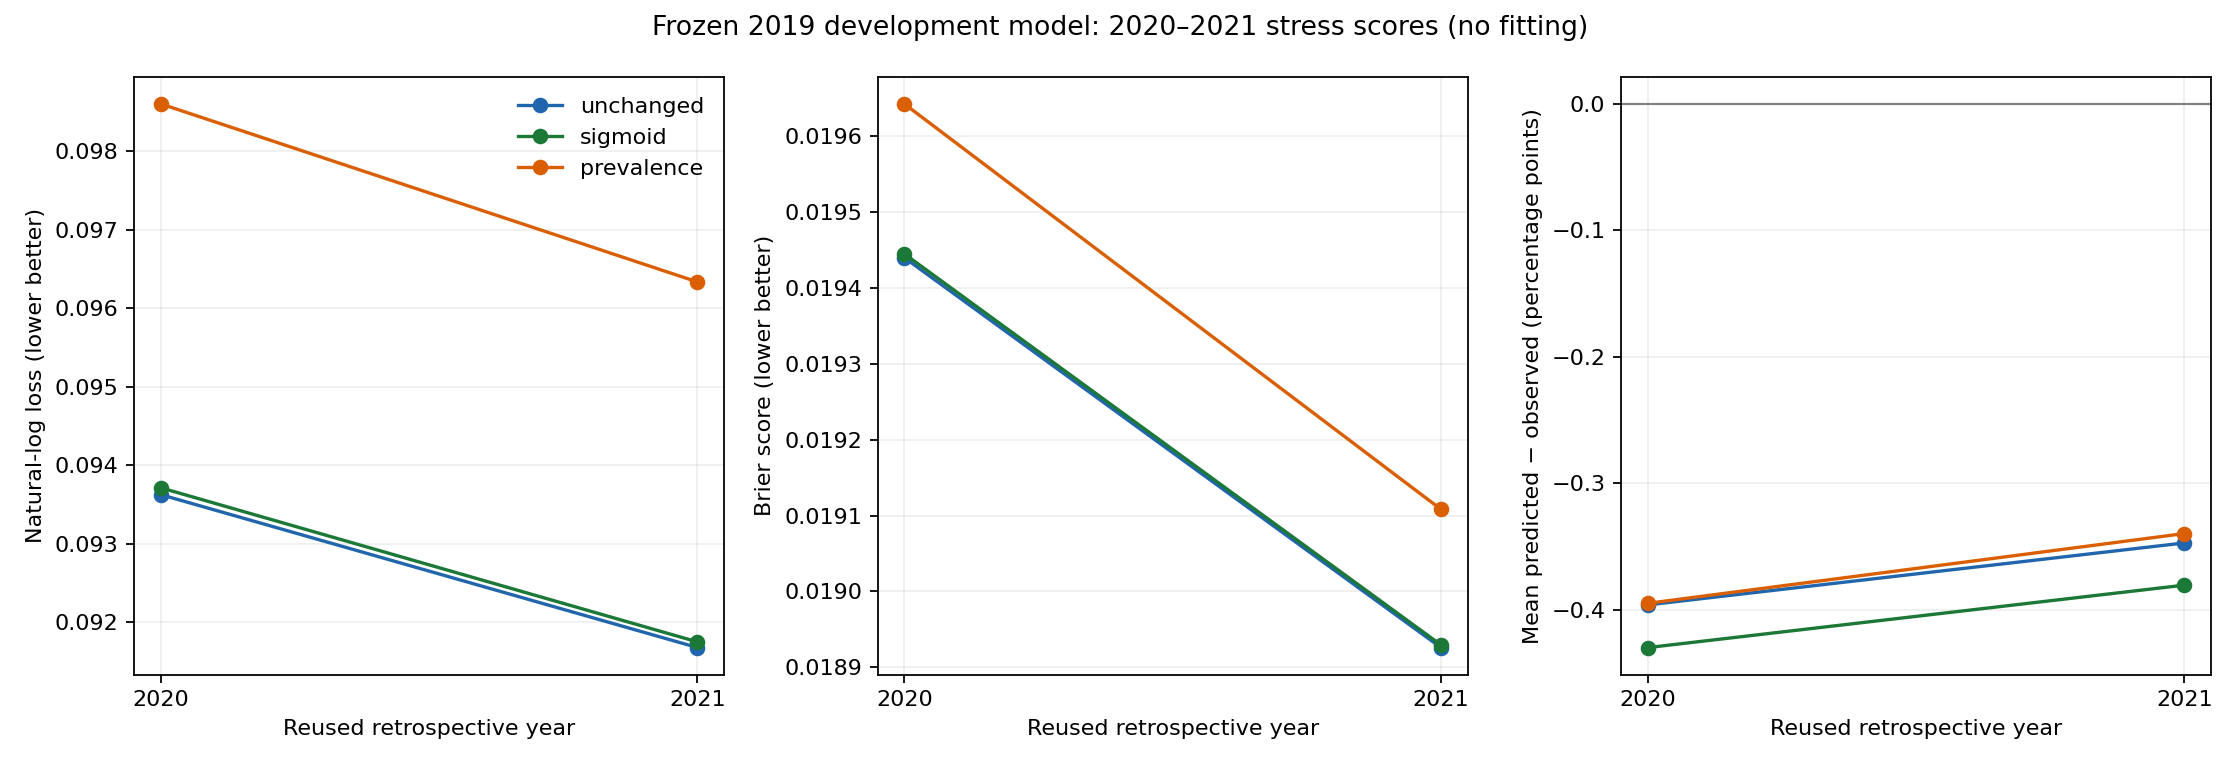

In [5]:
display(all_rows[['population','method','mean_prediction','observed_prevalence','prediction_minus_observed','observed_expected_ratio']])
figure('cstress_v1_scores.png')

### Reliability and sparse support

Full fixed-bin range is shown alongside a 0–10% low-probability zoom. Omitted-bin collision counts are labeled separately per method; these are not unique collisions summed across methods. Crosses identify sparse bins. Empty bins remain in the full CSV evidence.

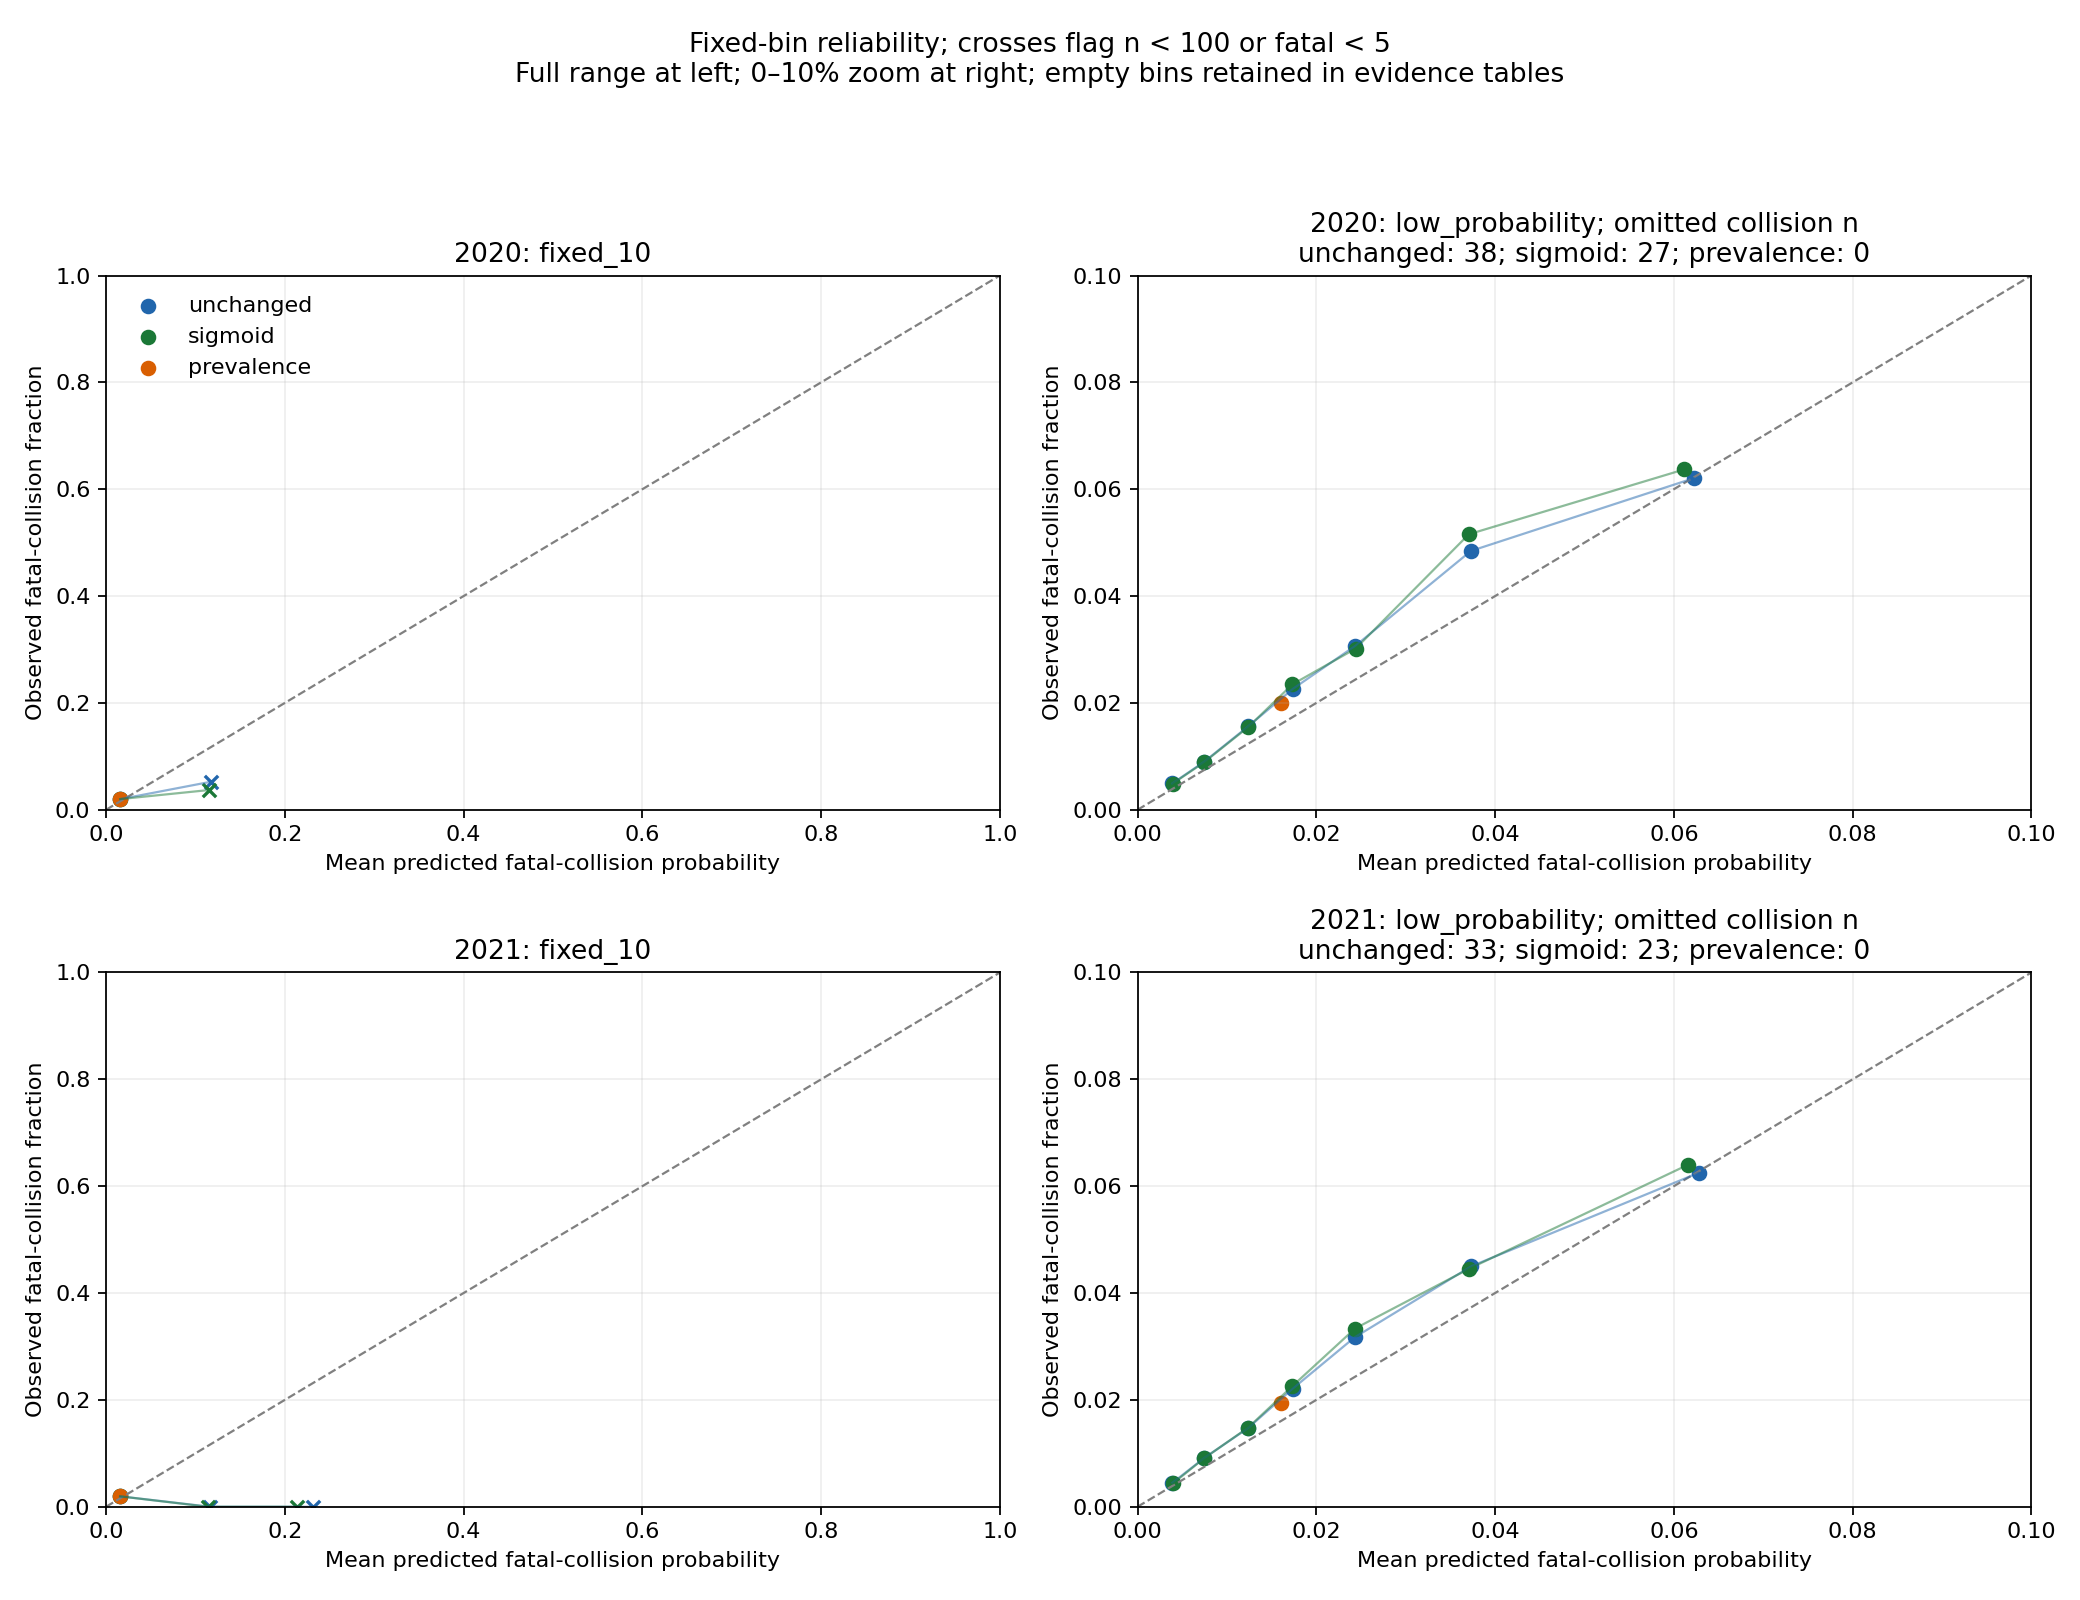

In [6]:
figure('cstress_v1_reliability.png')

In [7]:
bins=table('cstress_v1_reliability.csv')
display(bins[bins.population.eq('pooled') & bins.scheme.eq('low_probability') & bins.n.gt(0)])
display(table('cstress_v1_ece.csv'))

,population,method,scheme,bin,left,right,n,fatal,mean_prediction,observed_fraction,sparse_n_lt_100_or_fatal_lt_5
136,pooled,unchanged,low_probability,0,0.000,0.005,26759,126,0.003896,0.004709,False
137,pooled,unchanged,low_probability,1,0.005,0.010,35680,323,0.007449,0.009053,False
138,pooled,unchanged,low_probability,2,0.010,0.015,29652,449,0.012360,0.015142,False
139,pooled,unchanged,low_probability,3,0.015,0.020,27973,625,0.017349,0.022343,False
140,pooled,unchanged,low_probability,4,0.020,0.030,24518,765,0.024321,0.031202,False
141,pooled,unchanged,low_probability,5,0.030,0.050,15347,717,0.037324,0.046719,False
142,pooled,unchanged,low_probability,6,0.050,0.100,3580,223,0.062513,0.062291,False
143,pooled,unchanged,low_probability,7,0.100,0.200,70,2,0.117057,0.028571,True
144,pooled,unchanged,low_probability,8,0.200,0.300,1,0,0.231094,0.000000,True
157,pooled,sigmoid,low_probability,0,0.000,0.005,25631,119,0.003962,0.004643,False


,population,method,scheme,n,ece
0,2020,prevalence,fixed_10,79990,0.003947
1,2020,prevalence,low_probability,79990,0.003947
2,2020,sigmoid,fixed_10,79990,0.004350
3,2020,sigmoid,low_probability,79990,0.004350
4,2020,unchanged,fixed_10,79990,0.004022
5,2020,unchanged,low_probability,79990,0.004029
6,2021,prevalence,fixed_10,83590,0.003396
7,2021,prevalence,low_probability,83590,0.003396
8,2021,sigmoid,fixed_10,83590,0.003869
9,2021,sigmoid,low_probability,83590,0.003869


### Availability groups and source coverage

Unknown, other and unavailable flags overlap; there is no priority-based mutually exclusive recoding. Every feature also has all four availability classes, including zero-support groups. Feature tables overlap and must not be added as counts of unique collisions.

In [8]:
display(metrics[metrics.population.eq('pooled') & metrics['group'].isin(['has_unknown=True','has_other=True','has_unavailable=True'])][['group','method','n','fatal','log_loss','brier_score','mean_prediction','observed_prevalence','sparse_n_lt_100_or_fatal_lt_5']])
display(table('cstress_v1_membership.csv'))

,group,method,n,fatal,log_loss,brier_score,mean_prediction,observed_prevalence,sparse_n_lt_100_or_fatal_lt_5
264,has_unknown=True,unchanged,24303,459,0.089186,0.018350,0.014367,0.018887,False
265,has_unknown=True,sigmoid,24303,459,0.089292,0.018356,0.014120,0.018887,False
266,has_unknown=True,prevalence,24303,459,0.093909,0.018538,0.016080,0.018887,False
270,has_other=True,unchanged,14944,295,0.091117,0.019124,0.017263,0.019740,False
271,has_other=True,sigmoid,14944,295,0.091239,0.019130,0.016888,0.019740,False
272,has_other=True,prevalence,14944,295,0.097422,0.019364,0.016080,0.019740,False
276,has_unavailable=True,unchanged,0,0,NaN,NaN,NaN,NaN,True
277,has_unavailable=True,sigmoid,0,0,NaN,NaN,NaN,NaN,True
278,has_unavailable=True,prevalence,0,0,NaN,NaN,NaN,NaN,True


,population,source_id,source_year,n,fatal,nonfatal
0,2020,2164b2a7-a580-4708-bdac-8ab0c1304bc2,2020,79990,1602,78388
1,2021,f964d00f-6bba-44be-ae79-85f574d04a31,2021,83590,1628,81962
2,pooled,2164b2a7-a580-4708-bdac-8ab0c1304bc2,2020,79990,1602,78388
3,pooled,f964d00f-6bba-44be-ae79-85f574d04a31,2021,83590,1628,81962


### Two-year macro summary

The equal-year macro summary is descriptive. Its sample SD is not a confidence interval. The assessment still requires both annual gates, and pooled results do not supply independent corroboration.

In [9]:
macro=table('cstress_v1_macro.csv')
display(macro[['method','log_loss_mean','log_loss_std','brier_score_mean','brier_score_std','average_precision_mean','roc_auc_mean']])

,method,log_loss_mean,log_loss_std,brier_score_mean,brier_score_std,average_precision_mean,roc_auc_mean
0,prevalence,0.097469,0.001604,0.019375,0.000377,0.019752,0.500000
1,sigmoid,0.092728,0.001389,0.019187,0.000364,0.042177,0.699176
2,unchanged,0.092648,0.001378,0.019183,0.000363,0.042177,0.699176


## Takeaways

1. The previously selected sigmoid adjustment does not transfer favorably under the frozen two-year rule: both proper scores worsen in both years.
2. Underprediction increases. Ranking remains unchanged, as expected for a positive monotone transformation of one fixed estimator.
3. Preserve the original baseline as a comparison reference with its existing limitations; neither score variant is promoted to deployment.
4. Do not retune on these stress outcomes. Further fitting requires a separately disclosed design; newer audited record-level or prospective data would strengthen independent evaluation.

The notebook executes and saves tables and figures after verifying the prior full audit receipt. Standalone plots are visually inspected separately. Whole-notebook page rendering remains unverified because of the previously recorded local browser URL-policy restriction.